# Лабораторная работа 4. Функции активации и градиенты
Оспан Әсел Ғалымжанқызы · Казахский национальный университет имени аль-Фараби

Проверьте шесть функций в нескольких точках, затем сравните ReLU и сигмоиду
в одной и той же многослойной модели. В ячейках приведён полный код.
Для второго этапа требуются PyTorch и четыре файла Fashion-MNIST либо доступ к репозиторию набора.

## 1. Значения и производные
В гладкой точке сравните ручную формулу, autograd и
$[f(z+\varepsilon)-f(z-\varepsilon)]/(2\varepsilon)$ при $\varepsilon=10^{-5}$.
Для ReLU и Leaky ReLU при $z=0$ выпишите два односторонних наклона.

In [1]:
"""Ручные производные активаций и проверка в PyTorch."""

import math

import torch
from torch.nn import functional as F


FUNCTIONS = ("sigmoid", "tanh", "relu", "leaky_relu", "elu", "softplus")
POINTS = (-6, -2, 0, 2, 6)
ALPHA = 0.1


def value(name, z):
    if name == "sigmoid":
        if z >= 0:
            return 1 / (1 + math.exp(-z))
        exp_z = math.exp(z)
        return exp_z / (1 + exp_z)
    if name == "tanh":
        return math.tanh(z)
    if name == "relu":
        return max(0.0, z)
    if name == "leaky_relu":
        return z if z >= 0 else ALPHA * z
    if name == "elu":
        return z if z >= 0 else math.expm1(z)
    if name == "softplus":
        # Устойчивая форма log(1 + exp(z)).
        return max(0.0, z) + math.log1p(math.exp(-abs(z)))
    raise ValueError(f"Неизвестная активация: {name}")


def derivative(name, z):
    """Классическая производная. None обозначает излом."""
    if name == "sigmoid":
        s = value(name, z)
        return s * (1 - s)
    if name == "tanh":
        return 1 - value(name, z) ** 2
    if name in ("relu", "leaky_relu"):
        if z == 0:
            return None
        if z > 0:
            return 1.0
        return 0.0 if name == "relu" else ALPHA
    if name == "elu":
        return 1.0 if z >= 0 else math.exp(z)
    if name == "softplus":
        return value("sigmoid", z)
    raise ValueError(f"Неизвестная активация: {name}")


def torch_value(name, tensor):
    if name == "leaky_relu":
        return F.leaky_relu(tensor, negative_slope=ALPHA)
    if name == "elu":
        return F.elu(tensor, alpha=1.0)
    if name == "softplus":
        return F.softplus(tensor, beta=1.0)
    functions = {"sigmoid": torch.sigmoid, "tanh": torch.tanh, "relu": torch.relu}
    return functions[name](tensor)


def autograd_derivative(name, z):
    x = torch.tensor(z, dtype=torch.float64, requires_grad=True)
    (gradient,) = torch.autograd.grad(torch_value(name, x), x)
    return gradient.item()


def central_difference(name, z, epsilon=1e-5):
    if epsilon <= 0:
        raise ValueError("epsilon должен быть положительным")
    return (value(name, z + epsilon) - value(name, z - epsilon)) / (2 * epsilon)


def one_sided(name, z, epsilon=1e-5):
    if epsilon <= 0:
        raise ValueError("epsilon должен быть положительным")
    center = value(name, z)
    left = (center - value(name, z - epsilon)) / epsilon
    right = (value(name, z + epsilon) - center) / epsilon
    return left, right


def activation_chain(name, depth=4, start=None):
    """Предактивации, смещение после первого слоя, ручная производная и autograd."""
    if depth < 1:
        raise ValueError("Число слоёв должно быть положительным")
    if start is None:
        start = 1.0 if name == "relu" else 0.0
    bias = start - value(name, start)
    x = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    preactivations = []
    current = x
    for layer in range(depth):
        z = current if layer == 0 else current + bias
        preactivations.append(z.item())
        current = torch_value(name, z)
    slopes = [derivative(name, z) for z in preactivations]
    manual = None if None in slopes else math.prod(slopes)
    (gradient,) = torch.autograd.grad(current, x)
    return preactivations, bias, manual, gradient.item()


def verify_examples():
    rows = []
    for name in FUNCTIONS:
        for z in POINTS:
            expected = derivative(name, z)
            auto = autograd_derivative(name, z)
            central = central_difference(name, z)
            actual = value(name, z)
            torch_actual = torch_value(name, torch.tensor(z, dtype=torch.float64)).item()
            assert math.isclose(actual, torch_actual, abs_tol=1e-12)
            if expected is not None:
                # При alpha=1 ELU имеет непрерывную первую производную в нуле.
                # На стыке у односторонних вторых производных разные значения.
                tolerance = 3e-6 if name == "elu" and z == 0 else 1e-9
                assert math.isclose(expected, auto, abs_tol=1e-12), (name, z)
                assert math.isclose(expected, central, abs_tol=tolerance), (name, z)
            rows.append((name, z, actual, expected, auto, central))
    assert one_sided("relu", 0) == (0.0, 1.0)
    assert math.isclose(central_difference("relu", 0), 0.5)
    assert autograd_derivative("relu", 0) == 0
    assert math.isclose(central_difference("leaky_relu", 0), 0.55)
    assert autograd_derivative("leaky_relu", 0) == ALPHA
    return rows

In [2]:
from IPython.display import Markdown, SVG, display

table = [
    "| Активация | z | f(z) | Ручная производная | Autograd | Центральная разность |",
    "|:---|---:|---:|---:|---:|---:|",
]
for name, z, actual, expected, auto, central in verify_examples():
    manual = "излом" if expected is None else f"{expected:.9f}"
    table.append(f"| {name} | {z} | {actual:.9f} | {manual} | {auto:.9f} | {central:.9f} |")
display(Markdown("\n".join(table)))
for name in ("relu", "leaky_relu"):
    left, right = one_sided(name, 0)
    print(f"{name}: слева={left:.2f}, справа={right:.2f}, "
          f"центр={central_difference(name, 0):.2f}, autograd={autograd_derivative(name, 0):.2f}")

| Активация | z | f(z) | Ручная производная | Autograd | Центральная разность |
|:---|---:|---:|---:|---:|---:|
| sigmoid | -6 | 0.002472623 | 0.002466509 | 0.002466509 | 0.002466509 |
| sigmoid | -2 | 0.119202922 | 0.104993585 | 0.104993585 | 0.104993585 |
| sigmoid | 0 | 0.500000000 | 0.250000000 | 0.250000000 | 0.250000000 |
| sigmoid | 2 | 0.880797078 | 0.104993585 | 0.104993585 | 0.104993585 |
| sigmoid | 6 | 0.997527377 | 0.002466509 | 0.002466509 | 0.002466509 |
| tanh | -6 | -0.999987712 | 0.000024577 | 0.000024577 | 0.000024577 |
| tanh | -2 | -0.964027580 | 0.070650825 | 0.070650825 | 0.070650825 |
| tanh | 0 | 0.000000000 | 1.000000000 | 1.000000000 | 1.000000000 |
| tanh | 2 | 0.964027580 | 0.070650825 | 0.070650825 | 0.070650825 |
| tanh | 6 | 0.999987712 | 0.000024577 | 0.000024577 | 0.000024577 |
| relu | -6 | 0.000000000 | 0.000000000 | 0.000000000 | 0.000000000 |
| relu | -2 | 0.000000000 | 0.000000000 | 0.000000000 | 0.000000000 |
| relu | 0 | 0.000000000 | излом | 0.000000000 | 0.500000000 |
| relu | 2 | 2.000000000 | 1.000000000 | 1.000000000 | 1.000000000 |
| relu | 6 | 6.000000000 | 1.000000000 | 1.000000000 | 1.000000000 |
| leaky_relu | -6 | -0.600000000 | 0.100000000 | 0.100000000 | 0.100000000 |
| leaky_relu | -2 | -0.200000000 | 0.100000000 | 0.100000000 | 0.100000000 |
| leaky_relu | 0 | 0.000000000 | излом | 0.100000000 | 0.550000000 |
| leaky_relu | 2 | 2.000000000 | 1.000000000 | 1.000000000 | 1.000000000 |
| leaky_relu | 6 | 6.000000000 | 1.000000000 | 1.000000000 | 1.000000000 |
| elu | -6 | -0.997521248 | 0.002478752 | 0.002478752 | 0.002478752 |
| elu | -2 | -0.864664717 | 0.135335283 | 0.135335283 | 0.135335283 |
| elu | 0 | 0.000000000 | 1.000000000 | 1.000000000 | 0.999997500 |
| elu | 2 | 2.000000000 | 1.000000000 | 1.000000000 | 1.000000000 |
| elu | 6 | 6.000000000 | 1.000000000 | 1.000000000 | 1.000000000 |
| softplus | -6 | 0.002475685 | 0.002472623 | 0.002472623 | 0.002472623 |
| softplus | -2 | 0.126928011 | 0.119202922 | 0.119202922 | 0.119202922 |
| softplus | 0 | 0.693147181 | 0.500000000 | 0.500000000 | 0.500000000 |
| softplus | 2 | 2.126928011 | 0.880797078 | 0.880797078 | 0.880797078 |
| softplus | 6 | 6.002475685 | 0.997527377 | 0.997527377 | 0.997527377 |

relu: слева=0.00, справа=1.00, центр=0.50, autograd=0.00
leaky_relu: слева=0.10, справа=1.00, центр=0.55, autograd=0.10


## 2. Градиент через четыре слоя
Положите вес каждого скалярного слоя равным 1. Чтобы сохранить выбранную
предактивацию $z_*$ после первого слоя, добавляйте смещение $z_*-f(z_*)$.
Для сигмоиды при $z_*=0$ это $-0{,}5$. Для tanh при нуле и ReLU при единице это 0.

In [3]:
for name, start in (("sigmoid", 0), ("tanh", 0), ("relu", 0), ("relu", 1)):
    zs, bias, manual, auto = activation_chain(name, start=start)
    print(f"{name}, z={zs}, b={bias:g}: ручная={manual}, autograd={auto:g}")
assert activation_chain("sigmoid")[2:] == (1 / 256, 1 / 256)
assert activation_chain("tanh")[2:] == (1, 1)
assert activation_chain("relu", start=0)[2:] == (None, 0)
assert activation_chain("relu", start=1)[2:] == (1, 1)

sigmoid, z=[0.0, 0.0, 0.0, 0.0], b=-0.5: ручная=0.00390625, autograd=0.00390625
tanh, z=[0.0, 0.0, 0.0, 0.0], b=0: ручная=1.0, autograd=1
relu, z=[0.0, 0.0, 0.0, 0.0], b=0: ручная=None, autograd=0
relu, z=[1.0, 1.0, 1.0, 1.0], b=0: ручная=1.0, autograd=1


## 3. Контролируемое сравнение ReLU и sigmoid
Две модели имеют одинаковые исходные веса, по четыре скрытых слоя ширины 128
и выход из десяти логитов. Пробный батч в обеих ветвях совпадает. Нормы весовых
градиентов измеряются до обновления у первого и четвёртого скрытых линейных слоёв.
Короткий запуск берёт 4096 тренировочных и 1024 валидационных объекта из двух
отдельных частей главы 2. Он проходит одну эпоху с размером батча 256.

Укажите DATA_DIR или переменную FASHION_MNIST_DIR. При первом запуске можно
установить DOWNLOAD = True для получения официальных файлов.

In [4]:
"""Сравнение Linear и MLP на официальном Fashion-MNIST."""

from copy import deepcopy
import gzip
from hashlib import md5
from pathlib import Path
import struct
from urllib.request import urlopen

import torch
from torch import nn
from torch.utils.data import DataLoader, Subset, TensorDataset


SOURCE = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
CHECKSUMS = {
    "train-images-idx3-ubyte.gz": "8d4fb7e6c68d591d4c3dfef9ec88bf0d",
    "train-labels-idx1-ubyte.gz": "25c81989df183df01b3e8a0aad5dffbe",
    "t10k-images-idx3-ubyte.gz": "bef4ecab320f06d8554ea6380940ec79",
    "t10k-labels-idx1-ubyte.gz": "bb300cfdad3c16e7a12a480ee83cd310",
}


def download_data(folder):
    folder.mkdir(parents=True, exist_ok=True)
    for name, digest in CHECKSUMS.items():
        target = folder / name
        if target.is_file() and md5(target.read_bytes()).hexdigest() == digest:
            continue
        with urlopen(SOURCE + name, timeout=60) as response:
            data = response.read()
        if md5(data).hexdigest() != digest:
            raise ValueError(f"Контрольная сумма не совпала: {name}")
        target.write_bytes(data)


def read_split(folder, prefix, count):
    with gzip.open(folder / f"{prefix}-images-idx3-ubyte.gz", "rb") as f:
        image_header = struct.unpack(">IIII", f.read(16))
        images = bytearray(f.read())
    with gzip.open(folder / f"{prefix}-labels-idx1-ubyte.gz", "rb") as f:
        label_header = struct.unpack(">II", f.read(8))
        labels = bytearray(f.read())
    if (image_header != (2051, count, 28, 28) or label_header != (2049, count)
            or len(images) != count * 784 or len(labels) != count):
        raise ValueError(f"Некорректный формат или размер IDX: {prefix}")

    x = torch.frombuffer(images, dtype=torch.uint8).reshape(count, 784)
    y = torch.frombuffer(labels, dtype=torch.uint8).long()
    if y.max().item() > 9:
        raise ValueError(f"Некорректные метки классов: {prefix}")
    return TensorDataset(x.float().div_(255), y)


def load_data(folder, seed):
    training = read_split(folder, "train", 60000)
    test = read_split(folder, "t10k", 10000)
    order = torch.randperm(len(training), generator=torch.Generator().manual_seed(seed))
    return Subset(training, order[:55000]), Subset(training, order[55000:]), test



@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()
    confusion = torch.zeros((10, 10), dtype=torch.long)
    for x, y in loader:
        predicted = model(x.to(device)).argmax(dim=1).cpu()
        confusion += torch.bincount(10 * y + predicted, minlength=100).reshape(10, 10)

    correct = confusion.diag()
    accuracy = correct.sum().item() / confusion.sum().item()
    denominator = confusion.sum(dim=0) + confusion.sum(dim=1)
    macro_f1 = (2 * correct / denominator.clamp_min(1)).mean().item()
    return accuracy, macro_f1, confusion


def fit(model, train_loader, val_loader, device, epochs):
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loss_function = nn.CrossEntropyLoss()
    best_accuracy, best_epoch = -1.0, 0
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = loss_function(model(x), y)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(y)

        accuracy, f1, _ = evaluate(model, val_loader, device)
        print(f"epoch={epoch} train_loss={total_loss / len(train_loader.dataset):.4f} "
              f"val_accuracy={accuracy:.4f} val_macro_f1={f1:.4f}")
        if accuracy > best_accuracy:
            best_accuracy, best_epoch = accuracy, epoch
            best_weights = deepcopy(model.state_dict())

    model.load_state_dict(best_weights)
    return best_epoch, best_accuracy



def build_models():
    def build(activation):
        layers = [nn.Linear(784, 128), activation()]
        for _ in range(3):
            layers.extend([nn.Linear(128, 128), activation()])
        return nn.Sequential(*layers, nn.Linear(128, 10))

    relu, sigmoid = build(nn.ReLU), build(nn.Sigmoid)
    sigmoid.load_state_dict(relu.state_dict())
    return {"ReLU": relu, "Sigmoid": sigmoid}


def probe_gradients(model, first_batch, device):
    """Вычисляет нормы градиентов весов до первого обновления."""
    x, y = (tensor.to(device) for tensor in first_batch)
    model.zero_grad(set_to_none=True)
    loss = nn.functional.cross_entropy(model(x), y)
    loss.backward()
    affine = [layer for layer in model if isinstance(layer, nn.Linear)]
    first = affine[0].weight.grad.norm().item()
    last = affine[-2].weight.grad.norm().item()
    model.zero_grad(set_to_none=True)
    return loss.item(), first, last


def make_train_loader(dataset, batch_size, seed):
    return DataLoader(
        dataset, batch_size=batch_size, shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )

In [5]:
import os

DATA_DIR = Path(os.environ.get("FASHION_MNIST_DIR", "fashion_mnist_data"))
DOWNLOAD = False
DEVICE = "cpu"  # При доступной CUDA можно выбрать "cuda".
EPOCHS = 1
TRAIN_LIMIT = 4096
VAL_LIMIT = 1024
BATCH_SIZE = 256
SEED = 42
if DOWNLOAD:
    download_data(DATA_DIR)
if any(not (DATA_DIR / name).is_file() for name in CHECKSUMS):
    raise FileNotFoundError("Укажите DATA_DIR с Fashion-MNIST или включите DOWNLOAD.")

torch.set_num_threads(2)
torch.manual_seed(SEED)
train_full, val_full, _ = load_data(DATA_DIR, SEED)
train = Subset(train_full, list(range(TRAIN_LIMIT)))
val = Subset(val_full, list(range(VAL_LIMIT)))
val_loader = DataLoader(val, batch_size=BATCH_SIZE)
diagnostic_batch = next(iter(make_train_loader(train, BATCH_SIZE, SEED)))
models = build_models()
initial = list(models["ReLU"].parameters())
other = list(models["Sigmoid"].parameters())
assert all(torch.equal(a, b) for a, b in zip(initial, other))
assert sum(p.numel() for p in initial) == 151306
print(f"train={len(train)}, val={len(val)}, batch={BATCH_SIZE}, seed={SEED}")
print("Проверено совпадение всех начальных весов и смещений.")

train=4096, val=1024, batch=256, seed=42
Проверено совпадение всех начальных весов и смещений.


In [6]:
diagnostics = {}
validation = {}
for name, model in models.items():
    print(name)
    model.to(DEVICE)
    diagnostics[name] = probe_gradients(model, diagnostic_batch, DEVICE)
    loss, first, last = diagnostics[name]
    print(f"initial_loss={loss:.6f}, grad_first={first:.6e}, grad_last_hidden={last:.6e}")
    training_loader = make_train_loader(train, BATCH_SIZE, SEED)
    best_epoch, best_accuracy = fit(model, training_loader, val_loader, DEVICE, EPOCHS)
    validation[name] = best_accuracy
print("Валидационная accuracy:", validation)
print(f"PyTorch {torch.__version__} | {DEVICE}")

ReLU
initial_loss=2.299028, grad_first=5.088041e-02, grad_last_hidden=1.773032e-02


epoch=1 train_loss=2.0617 val_accuracy=0.4473 val_macro_f1=0.3436
Sigmoid
initial_loss=2.314481, grad_first=7.801835e-04, grad_last_hidden=6.288653e-02
epoch=1 train_loss=2.3061 val_accuracy=0.0928 val_macro_f1=0.0170
Валидационная accuracy: {'ReLU': 0.447265625, 'Sigmoid': 0.0927734375}
PyTorch 2.10.0+cpu | cpu


## 4. Нормы на первом батче
По вертикали отложена норма Фробениуса весового градиента в логарифмическом
масштабе. Сравните первый и четвёртый скрытые слои. Масштабирование графика
помогает видеть малые значения, а числа над маркерами дают точные ориентиры.

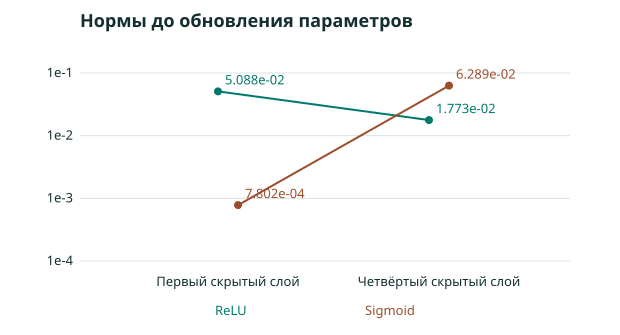

In [7]:
positive = [max(v, 1e-15) for _, first, last in diagnostics.values() for v in (first, last)]
low = math.floor(math.log10(min(positive)))
high = max(low + 1, math.ceil(math.log10(max(positive))))
y_coord = lambda val: 261 - 188 * (math.log10(max(val, 1e-15)) - low) / (high - low)
marks = []
for exp in range(low, high + 1):
    y = y_coord(10.0 ** exp)
    marks.append(f'<path d="M80 {y} H570" stroke="#d9e3e4"/>')
    marks.append(f'<text x="73" y="{y+4}" text-anchor="end">1e{exp}</text>')
for i, (name, color) in enumerate((("ReLU", "#00796d"), ("Sigmoid", "#9b4d2d"))):
    _, first, last = diagnostics[name]
    xs = 218 + 20 * i, 429 + 20 * i
    ys = y_coord(first), y_coord(last)
    marks.append(f'<path d="M{xs[0]} {ys[0]} L{xs[1]} {ys[1]}" stroke="{color}" stroke-width="2"/>')
    for x, y, val in zip(xs, ys, (first, last)):
        marks.append(f'<circle cx="{x}" cy="{y}" r="4" fill="{color}"/>')
        marks.append(f'<text x="{x+7}" y="{y-7}" fill="{color}">{val:.3e}</text>')
    marks.append(f'<text x="{215+150*i}" y="315" fill="{color}">{name}</text>')
svg = (
    '<svg xmlns="http://www.w3.org/2000/svg" width="620" height="335" '
    'viewBox="0 0 620 335" font-family="sans-serif" font-size="13" fill="#132e31" '
    'role="img" aria-label="Нормы градиентов ReLU и sigmoid на первом батче">'
    '<rect width="620" height="335" fill="white"/>'
    '<text x="80" y="27" font-size="18" font-weight="bold">Нормы до обновления параметров</text>'
    '<text x="228" y="286" text-anchor="middle">Первый скрытый слой</text>'
    '<text x="439" y="286" text-anchor="middle">Четвёртый скрытый слой</text>'
    + "".join(marks) + "</svg>"
)
display(SVG(svg))

## 5. Самостоятельная работа
**A.** Заполните таблицу $f(z)$ и производных для $z=-2,0,2$.
В изломах сравните односторонние наклоны, центральную разность и autograd.

**B.** Повторите численную проверку при двух других $\varepsilon$ и проследите
цепочки глубины 1, 2, 4 и 8. Сопоставьте результаты для сигмоиды и tanh.

**C.** Запустите обе модели на 55 000 и 5 000 объектах в течение пяти эпох.
Сопоставьте валидацию и нормы на первом батче. Повторите с другим seed
и укажите, какие различия сохранились.

Методический источник — «Семинар ДЛ 4.docx». Сравнение активаций проведено на
[Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist) по протоколу предыдущих глав.